# A tour of SADIE

**SADIE** (*Simulation, Analysis, and Design In Ecohydraulics*) predicts how much a patch
of vegetation (mangroves, salt marsh, seagrass, or a plant you describe yourself) calms
the waves passing through it.

The idea in one paragraph: a wave carries energy. When it passes through plants, the water
sloshing back and forth drags on every root, stem and leaf, and that drag turns some of
the wave's energy into heat and turbulence. Less energy means a smaller wave. SADIE adds
up that drag, layer by layer from the seabed to the water surface, and tracks how the wave
shrinks as it travels through the patch.

This notebook shows everything SADIE can do today:

1. [The water](#1-the-water): density and viscosity of fresh and salt water.
2. [The waves](#2-the-waves): how fast water moves under a wave, and when the theory holds.
3. [The plants](#3-the-plants): mangroves built from roots, stems and canopies.
4. [Sending a wave through a forest](#4-sending-a-wave-through-a-forest)
5. [Where the energy goes](#5-where-the-energy-goes)
6. [Drag coefficients from the literature](#6-drag-coefficients-from-the-literature)
7. [Exploring designs](#7-exploring-designs)
8. [From the lab to the real world](#8-from-the-lab-to-the-real-world): scaling.
9. [Your own plant, your own data](#9-your-own-plant-your-own-data)

Most examples use the 1:10 scale mangrove models of Zhang et al. (2023), *Coastal
Engineering* 186, 104403 ([doi:10.1016/j.coastaleng.2023.104403](https://doi.org/10.1016/j.coastaleng.2023.104403)),
which come built in. The equations behind every step are on the [theory](../theory.md) page.

In [1]:
import dataclasses
import warnings

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

import sadiepy as sd
from sadiepy.presets.zhang2023 import N_TREES
from sadiepy.scaling import froude

# Some examples deliberately go outside a closure's fitted range; SADIE records that
# on each result. Silence the repeated warnings to keep the page readable.
warnings.simplefilter("ignore", sd.ValidityWarning)  # includes ExtrapolationWarning

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "0.92",
        "axes.axisbelow": True,
        "font.size": 10,
        "axes.titlesize": 10,
        "axes.titleweight": "bold",
        "legend.frameon": False,
    }
)
# Colour-blind-safe categorical slots (validated) for the three mangrove models ...
CFG = {"M1": "#2a78d6", "M2": "#eb6834", "M3": "#1baf7a"}
MARK = {"M1": "o", "M2": "s", "M3": "^"}
# ... a second validated set for the parts of a tree ...
PART = {"root": "#6250d6", "stem": "#eda100", "canopy": "#008300"}
# ... a single-hue ramp for magnitudes, and status colours for "is it valid?".
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
GOOD, WARN, CRIT = "#0ca30c", "#fab219", "#d03b3b"

water = sd.Water(temperature=20.0)  # fresh flume water at 20 °C
PLANTS = {c: sd.presets.zhang2023(c) for c in CFG}
print("sadiepy", sd.__version__)

sadiepy 0.0.1.dev0


## 1. The water

Everything starts with the water. Its **density** sets how much energy a wave carries,
and its **viscosity** (how "thick" it is) sets the Reynolds number, which some drag laws
depend on. SADIE computes both from temperature and salinity using the seawater
correlations of Sharqawy et al. (2010). Warm water is runnier than cold water: at 30 °C
its viscosity is about 30 % lower than at 10 °C, which matters when you compare a lab
flume with a tropical coast.

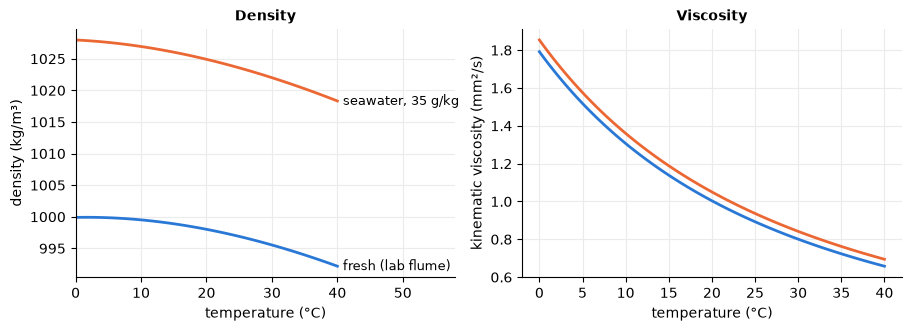

In [2]:
temps = np.linspace(0, 40, 81)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2), layout="constrained")
for sal, label, color in (
    (0.0, "fresh (lab flume)", CFG["M1"]),
    (35.0, "seawater, 35 g/kg", CFG["M2"]),
):
    ws = [sd.Water(temperature=t, salinity=sal) for t in temps]
    a1.plot(temps, [w.rho for w in ws], color=color, lw=2)
    a2.plot(temps, [w.nu * 1e6 for w in ws], color=color, lw=2)
    a1.annotate(
        label,
        (temps[-1], ws[-1].rho),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )
a1.set(xlabel="temperature (°C)", ylabel="density (kg/m³)", title="Density", xlim=(0, 58))
a2.set(xlabel="temperature (°C)", ylabel="kinematic viscosity (mm²/s)", title="Viscosity")
plt.show()

## 2. The waves

SADIE uses **linear wave theory**, the standard engineering description of a regular
wave. Given a wave height *H*, period *T* and water depth *h*, it works out the wavelength,
the speed at which the wave's energy travels, and how fast the water moves at every height.

That last point matters most for plants. Under a wave, water moves back and forth fastest
near the surface and slowest near the bed. Short waves are "felt" mostly near the surface;
long waves move the whole water column. A canopy near the surface therefore feels much
stronger flow than roots on the bed, and drag grows with the **cube** of the velocity.

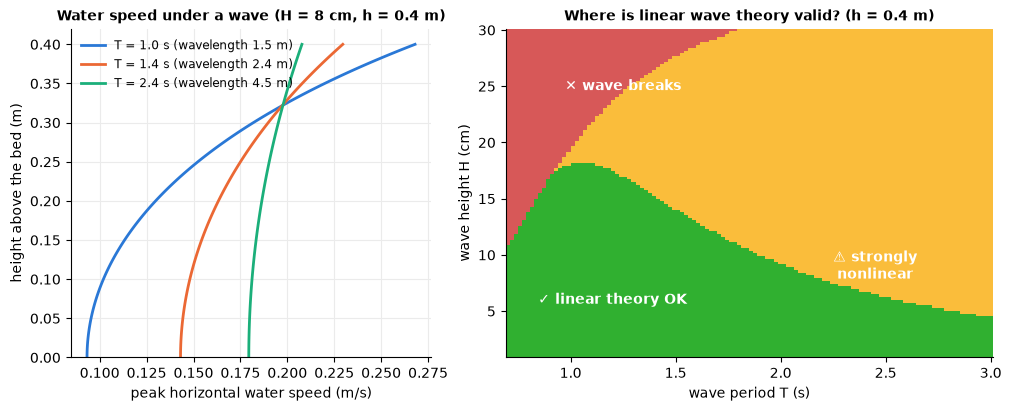

In [3]:
fig, (a1, a2) = plt.subplots(
    1, 2, figsize=(10, 4), layout="constrained", gridspec_kw={"width_ratios": [1, 1.35]}
)
s = np.linspace(0, 0.4, 100)
for T, color in zip((1.0, 1.4, 2.4), (CFG["M1"], CFG["M2"], CFG["M3"]), strict=True):
    w = sd.RegularWave(H=0.08, T=T, depth=0.4)
    a1.plot(w.u_m(s), s, color=color, lw=2, label=f"T = {T} s (wavelength {w.L:.1f} m)")
a1.legend(loc="upper left", fontsize=8.5)
a1.set(
    xlabel="peak horizontal water speed (m/s)",
    ylabel="height above the bed (m)",
    title="Water speed under a wave (H = 8 cm, h = 0.4 m)",
    ylim=(0, 0.42),
)

# When does linear theory hold? Check every (T, H) pair at h = 0.4 m.
Ts, Hs = np.linspace(0.7, 3.0, 120), np.linspace(0.01, 0.3, 120)
status = np.zeros((Hs.size, Ts.size))
for i, H in enumerate(Hs):
    for j, T in enumerate(Ts):
        issues = " ".join(sd.RegularWave(H=H, T=T, depth=0.4).validity_issues())
        status[i, j] = 2 if "breaking" in issues else (1 if issues else 0)
a2.pcolormesh(
    Ts,
    Hs * 100,
    status,
    cmap=ListedColormap([GOOD, WARN, CRIT]),
    vmin=0,
    vmax=2,
    shading="auto",
    alpha=0.85,
)
for x, y, txt in (
    (1.2, 6, "✓ linear theory OK"),
    (2.45, 9, "⚠ strongly\nnonlinear"),
    (1.25, 25, "✕ wave breaks"),
):
    a2.text(x, y, txt, ha="center", va="center", fontsize=10, color="white", weight="bold")
a2.set(
    xlabel="wave period T (s)",
    ylabel="wave height H (cm)",
    title="Where is linear wave theory valid? (h = 0.4 m)",
)
a2.grid(False)
plt.show()

SADIE runs these checks on every simulation and **warns** when a wave is about to
break or is too nonlinear for the theory. It doesn't silently return a number.

## 3. The plants

In SADIE a plant is a **stack of layers**. Each layer says how high it reaches, how many
elements stand on each square metre of seabed, and how wide each element looks to the
oncoming water. The width can change with height, which is how the inverted-cone canopy
below is described.

The built-in Zhang et al. (2023) mangroves, at 1:10 scale, are 40 cm trees on a 2 m patch,
36 trees per m²:

- **M1**: 28 prop roots and a stem;
- **M2**: M1 plus a sparse canopy of branches, twigs and leaves;
- **M3**: M1 plus a dense canopy, twice as leafy as M2.

The silhouettes show how wide one tree looks to the water at each height (the roots are
added up side by side). The dashed lines are the three water depths tested.

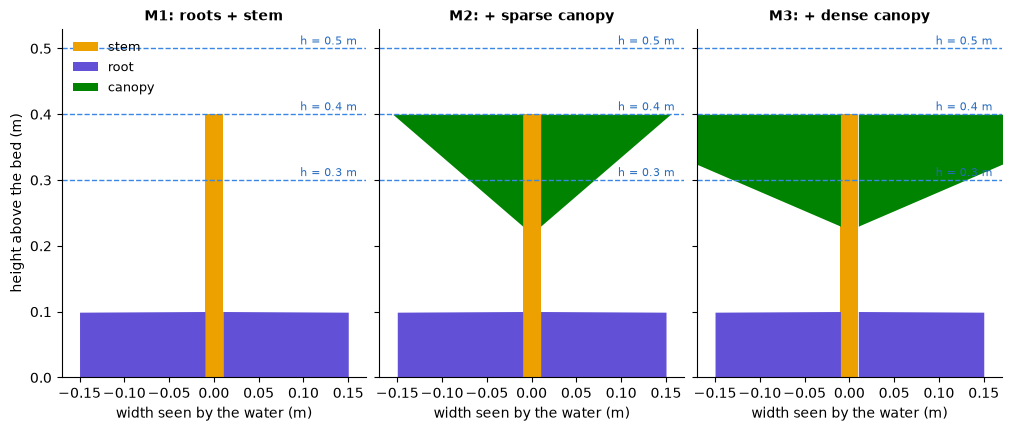

In [4]:
def silhouette(ax, plant, title):
    s = np.linspace(0, plant.height, 400)
    left = np.zeros_like(s)
    order = {"stem": 0, "roots": 1, "root": 1}  # stem in the middle, then roots, then canopy
    for layer in sorted(plant.layers, key=lambda lay: order.get(lay.name, 2)):
        part = "root" if "root" in layer.name else ("canopy" if "canopy" in layer.name else "stem")
        width = np.array([layer.n_per_m2 * layer.width_at(si) for si in s]) / N_TREES
        ax.fill_betweenx(s, left, left + width, color=PART[part], lw=0, label=part)
        ax.fill_betweenx(s, -left, -left - width, color=PART[part], lw=0)
        left = left + width
    for h in (0.3, 0.4, 0.5):
        ax.axhline(h, color="#3987e5", ls="--", lw=1)
        ax.text(0.16, h + 0.006, f"h = {h} m", fontsize=8, color="#256abf", ha="right")
    ax.set(title=title, xlim=(-0.17, 0.17), ylim=(0, 0.53), xlabel="width seen by the water (m)")
    ax.grid(False)


fig, axes = plt.subplots(1, 3, figsize=(10, 4.2), sharey=True, layout="constrained")
for ax, (c, plant) in zip(axes, PLANTS.items(), strict=True):
    silhouette(
        ax,
        plant,
        {"M1": "M1: roots + stem", "M2": "M2: + sparse canopy", "M3": "M3: + dense canopy"}[c],
    )
axes[0].set_ylabel("height above the bed (m)")
axes[0].legend(*axes[-1].get_legend_handles_labels(), loc="upper left", fontsize=9)
plt.show()

From the same description SADIE derives the quantities used to characterise
vegetation: the frontal area that faces the flow, the fraction of the water volume the
plants take up (*SVF*), and the characteristic lengths the drag laws use. All of them
change with water depth, because only the submerged part of a plant counts.

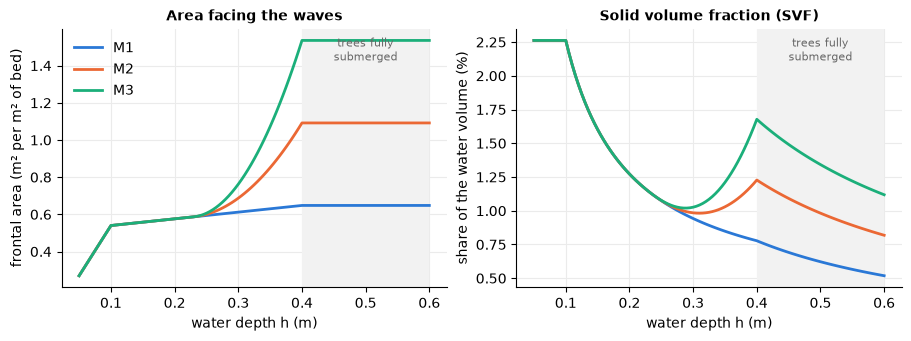

Characteristic lengths at h = 0.4 m (used by drag laws):
  M1: l_e = 0.48 cm, l_ew = 61.2 cm, r_v = 100.2 cm
  M2: l_e = 0.45 cm, l_ew = 36.2 cm, r_v = 63.2 cm
  M3: l_e = 0.44 cm, l_ew = 25.6 cm, r_v = 46.0 cm


In [5]:
depths = np.linspace(0.05, 0.6, 111)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.3), layout="constrained")
for c, plant in PLANTS.items():
    a1.plot(depths, [plant.frontal_area(h) for h in depths], color=CFG[c], lw=2, label=c)
    a2.plot(depths, [100 * plant.svf(h) for h in depths], color=CFG[c], lw=2, label=c)
for ax in (a1, a2):
    ax.axvspan(0.4, 0.6, color="0.95", lw=0)
    ax.text(
        0.5,
        0.97,
        "trees fully\nsubmerged",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=8,
        color="0.4",
    )
    ax.set_xlabel("water depth h (m)")
a1.set(ylabel="frontal area (m² per m² of bed)", title="Area facing the waves")
a2.set(ylabel="share of the water volume (%)", title="Solid volume fraction (SVF)")
a1.legend()
plt.show()

h = 0.4
print(f"Characteristic lengths at h = {h} m (used by drag laws):")
for c, plant in PLANTS.items():
    print(
        f"  {c}: l_e = {100 * plant.l_e(h):.2f} cm, l_ew = {100 * plant.l_ew(h):.1f} cm, "
        f"r_v = {100 * plant.hydraulic_radius(h):.1f} cm"
    )

## 4. Sending a wave through a forest

Now the main event. An 8 cm wave with a 1.4 s period meets the 2 m patch in 0.4 m of
water. SADIE solves the energy balance along the patch and returns the wave height at
every point. The drag coefficient comes from Zhang et al.'s own drag law
(`zhang2023_kc`, section 6), used the way they fitted it: from the incoming wave, with the
plant's frontal area averaged over the depth.

The picture shows a snapshot of the water surface, with its envelope, the largest height
reached at each point. Before the patch the wave is unchanged. Inside it the wave loses
height. Behind it, the calmer water is what a shoreline would see.

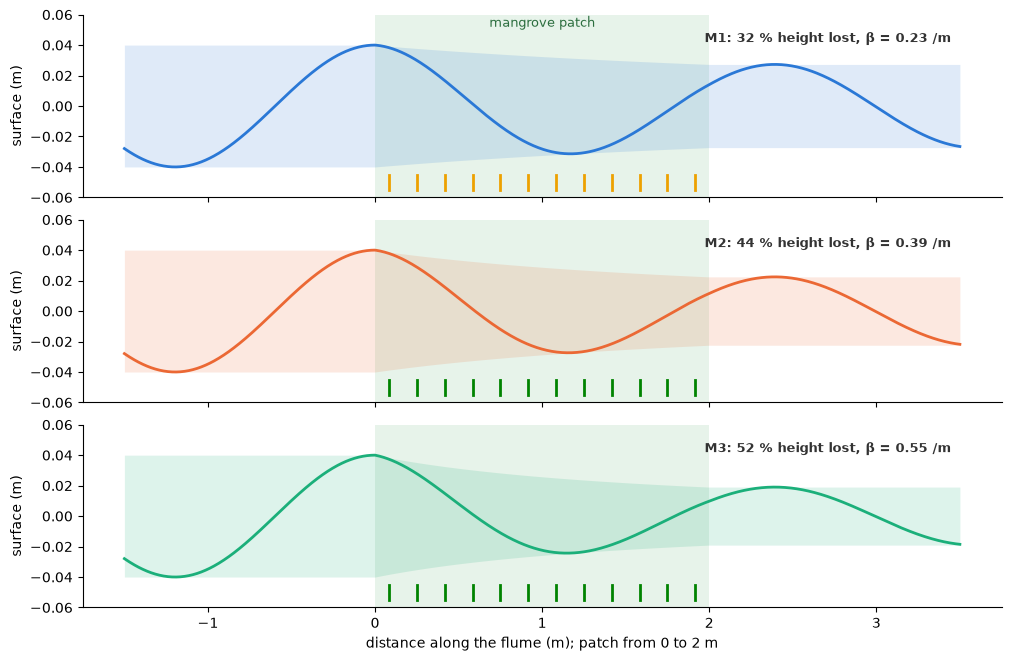

In [6]:
wave = sd.RegularWave(H=0.08, T=1.4, depth=0.4)
x_in = np.linspace(0, 2.0, 201)
ZHANG = {"drag": "zhang2023_kc", "cd_evaluation": "incident", "scale": 10.0}
runs = {
    c: sd.propagate(wave, p.depth_averaged(wave.depth), 2.0, water=water, x_out=x_in, **ZHANG)
    for c, p in PLANTS.items()
}

fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True, sharey=True, layout="constrained")
x = np.linspace(-1.5, 3.5, 1000)
for ax, (c, res) in zip(axes, runs.items(), strict=True):
    H = np.interp(x, res.x, res.H, left=wave.H, right=res.H[-1])
    ax.axvspan(0, 2, color="#e7f3ea", lw=0)
    for xt in np.arange(1 / 12, 2, 1 / 6):  # tree rows, 0.167 m apart
        ax.plot([xt, xt], [-0.055, -0.045], color=PART["canopy" if c != "M1" else "stem"], lw=2)
    ax.fill_between(x, -H / 2, H / 2, color=CFG[c], alpha=0.15, lw=0)
    ax.plot(x, H / 2 * np.cos(wave.k * x), color=CFG[c], lw=2)
    ax.text(
        3.45,
        0.042,
        f"{c}: {100 * (1 - res.H[-1] / wave.H):.0f} % height lost, β = {res.beta:.2f} /m",
        ha="right",
        fontsize=9,
        weight="bold",
        color="0.2",
    )
    ax.set_ylabel("surface (m)")
    ax.grid(False)
axes[0].text(1.0, 0.052, "mangrove patch", ha="center", fontsize=9, color="#2c6e3f")
axes[-1].set(xlabel="distance along the flume (m); patch from 0 to 2 m", ylim=(-0.06, 0.06))
plt.show()

SADIE sums the result up in one number, the **damping factor β**: the wave height
follows $H(x) = H_0 / (1 + \beta x)$, so a bigger β means faster calming. The dense canopy
(M3) more than doubles β compared with roots and stems alone (M1).

Every result also says how it was computed, so nothing is hidden:

In [7]:
res = runs["M3"]
layer = next(iter(res.drag_used))
print(f"method:                {res.method} (constant C_D, so the exact formula is used)")
print(f"drag law used:         {res.drag_used[layer]} ({res.drag_mode}, for the whole plant)")
print(f"C_D:                   {res.drag_coefficients[layer][0]:.2f}")
print(f"KC at the inlet:       {res.dimensionless['KC[zhang2023_kc]']['range'][0]:.1f}")
print(f"outside fitted range?  {res.extrapolated}")

method:                analytic (constant C_D, so the exact formula is used)
drag law used:         zhang2023_kc (bulk, for the whole plant)
C_D:                   6.47
KC at the inlet:       23.9
outside fitted range?  False


## 5. Where the energy goes

Because SADIE resolves the plant from bed to surface, it can tell you **which part of the
plant does the work**. On the left is the drag loss at each height for M3 in 0.5 m of water.
The canopy dominates. It is wide, and it sits near the surface where the water moves
fastest; remember that drag grows with the cube of the speed.

On the right is each part's share of the total loss, for every model and depth. When the
water is shallow (0.3 m), only the bottom of the canopy is wet. Once the trees are fully
under water, the canopy does most of the work.

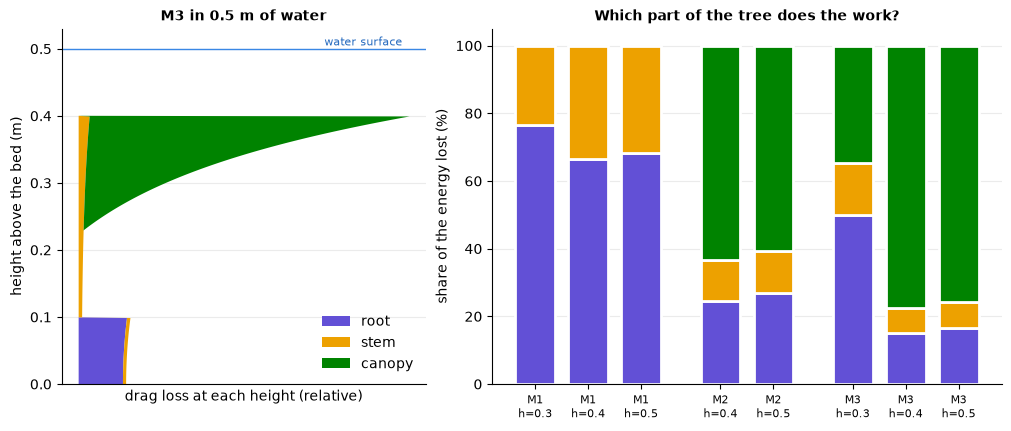

In [8]:
fig, (a1, a2) = plt.subplots(
    1, 2, figsize=(10, 4.2), layout="constrained", gridspec_kw={"width_ratios": [1, 1.4]}
)
w = sd.RegularWave(H=0.08, T=1.4, depth=0.5)
s = np.linspace(0, 0.5, 500)
left = np.zeros_like(s)
for layer in PLANTS["M3"].layers:
    part = layer.name if layer.name in PART else ("canopy" if "canopy" in layer.name else "stem")
    loss = np.array([layer.n_per_m2 * layer.width_at(si) for si in s]) * w.u_m(s) ** 3
    a1.fill_betweenx(s, left, left + loss, color=PART[part], lw=0, label=part)
    left = left + loss
a1.axhline(0.5, color="#3987e5", lw=1)
a1.text(left.max() * 0.98, 0.505, "water surface", ha="right", fontsize=8, color="#256abf")
a1.set(
    xlabel="drag loss at each height (relative)",
    ylabel="height above the bed (m)",
    title="M3 in 0.5 m of water",
    xticks=[],
    ylim=(0, 0.53),
)

labels, x0 = [], 0
for c, plant in PLANTS.items():
    for h in (0.3, 0.4, 0.5):
        if c == "M2" and h == 0.3:
            continue  # not tested by Zhang et al.
        f = sd.propagate(sd.RegularWave(0.08, 1.4, h), plant, 2.0, drag=1.0).layer_fractions
        bottom = 0.0
        for name, share in f.items():
            part = "root" if "root" in name else ("canopy" if "canopy" in name else "stem")
            a2.bar(
                x0,
                100 * share,
                bottom=bottom,
                color=PART[part],
                width=0.75,
                edgecolor="white",
                linewidth=2,
            )
            bottom += 100 * share
        labels.append((x0, f"{c}\nh={h}"))
        x0 += 1
    x0 += 0.5
a2.set_xticks([p for p, _ in labels], [t for _, t in labels], fontsize=8)
a2.set(ylabel="share of the energy lost (%)", title="Which part of the tree does the work?")
a2.grid(axis="x", visible=False)
a1.legend(loc="lower right")
plt.show()

SADIE also keeps a full **energy budget**: the energy the wave still carries plus
the energy lost to the plants must equal what came in. The check below shows that it
balances to within numerical precision. It is part of the test suite, too.

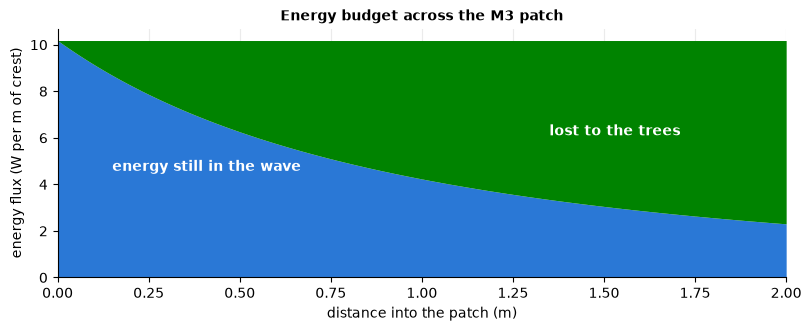

budget error: 5.2e-16 of the incoming energy


In [9]:
res = runs["M3"]
total = res.energy_flux + res.cumulative_dissipation
fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
ax.stackplot(
    res.x,
    res.energy_flux,
    res.cumulative_dissipation,
    colors=[CFG["M1"], PART["canopy"]],
    edgecolor="white",
    linewidth=0,
)
ax.text(0.15, res.energy_flux[0] * 0.45, "energy still in the wave", color="white", weight="bold")
ax.text(1.35, res.energy_flux[0] * 0.6, "lost to the trees", color="white", weight="bold")
ax.set(
    xlabel="distance into the patch (m)",
    ylabel="energy flux (W per m of crest)",
    title="Energy budget across the M3 patch",
    xlim=(0, 2),
)
plt.show()
print(f"budget error: {abs(total.max() - total.min()) / total[0]:.1e} of the incoming energy")

## 6. Drag coefficients from the literature

The key input is the **drag coefficient** $C_D$, the number that says how strongly the
water "grabs" the plants. It comes from experiments, usually as a formula in one dimensionless number:
the Reynolds number (Re), the Keulegan–Carpenter number (KC) or the Ursell number (Ur).

SADIE ships with all ten mangrove drag laws collected by Zhang et al. (2023, Table 3). Each
one remembers its source, the scale of the experiment, what it was fitted to, and the
range it is valid for. The shaded band in each panel is that range; SADIE warns you if you
go outside it.

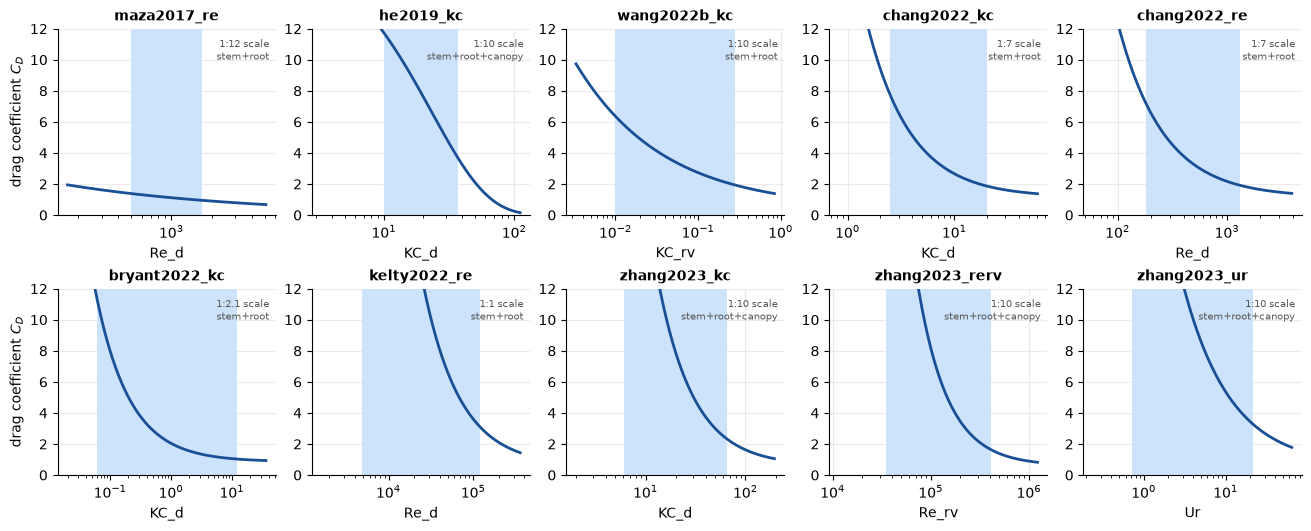

In [10]:
closures = [sd.drag.get(n) for n in sd.drag.names()]
fig, axes = plt.subplots(2, 5, figsize=(13, 5.2), layout="constrained")
for ax, cl in zip(axes.flat, closures, strict=True):
    lo, hi = cl.valid_range
    lo = max(lo, hi / 200)
    xs = np.geomspace(lo / 3, hi * 3, 200)
    ax.axvspan(lo, hi, color="#cde2fb", lw=0)
    ax.plot(xs, [cl(float(v)) for v in xs], color="#184f95", lw=2)
    ax.set(xscale="log", title=cl.name, ylim=(0, 12))
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    length = {"d": "d", "r_v": "rv", None: ""}.get(cl.length_scale, str(cl.length_scale))
    ax.set_xlabel(f"{cl.variable}{'_' + length if length else ''}")
    ax.text(
        0.97,
        0.95,
        f"1:{cl.scale:g} scale\n{cl.components}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=7.5,
        color="0.35",
    )
for ax in axes[:, 0]:
    ax.set_ylabel("drag coefficient $C_D$")
plt.show()

**Swapping drag laws takes one argument.** Below, the same wave and the same M3
forest are simulated with each of the ten laws, so you can see at a glance how sensitive a
design is to that choice. Hatched bars are laws used outside the range they were fitted
for, which SADIE flags automatically.

Every law is evaluated the way Zhang et al. analysed their data (depth-averaged plant,
$C_D$ taken at the incoming wave). Reynolds numbers are converted to the scale of each
source experiment, using SADIE's scaling tools (section 8).

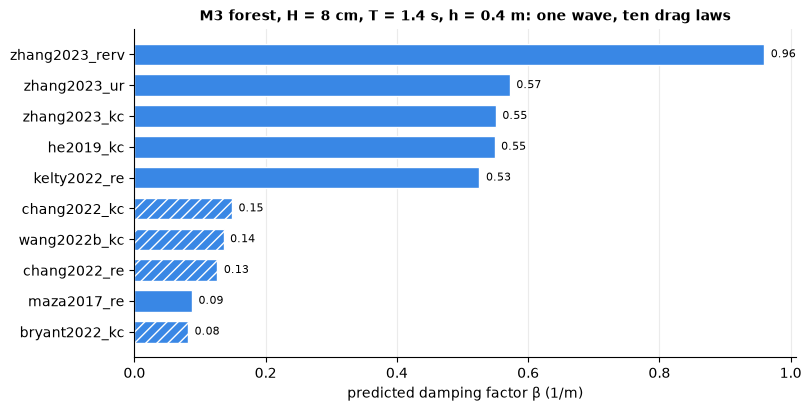

In [11]:
case, config = (0.08, 1.4, 0.4), "M3"
w = sd.RegularWave(*case)
veg = PLANTS[config].depth_averaged(w.depth)
rows = []
for name in sd.drag.names():
    r = sd.propagate(w, veg, 2.0, water=water, drag=name, cd_evaluation="incident", scale=10.0)
    rows.append((r.beta, name, r.extrapolated))
rows.sort()
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for i, (beta, _name, extrap) in enumerate(rows):
    ax.barh(
        i, beta, color="#3987e5", hatch="///" if extrap else None, edgecolor="white", height=0.7
    )
    ax.text(beta + 0.01, i, f"{beta:.2f}", va="center", fontsize=8)
ax.set_yticks(range(len(rows)), [n for _, n, _ in rows])
ax.set(
    xlabel="predicted damping factor β (1/m)",
    title="M3 forest, H = 8 cm, T = 1.4 s, h = 0.4 m: one wave, ten drag laws",
)
ax.grid(axis="y", visible=False)
plt.show()

## 7. Exploring designs

Because a simulation takes milliseconds, you can sweep through thousands of scenarios.
This is the start of SADIE's design side: working out *before* you build an experiment, or
plant a forest, which conditions matter.

**Left:** for the dense-canopy forest M3, how much of the wave survives a 2 m patch, across
every combination of wave period and water depth. The least wave gets through when the
water just reaches the tree tops (about 0.4 m): the whole canopy is wet and sits in the fast
flow near the surface. Deeper water lets the wave pass over the top, and in shallower water
part of the canopy is dry. Shorter waves are damped more. The white contours mark the share
of the wave height that gets through.

**Right:** how long a forest has to be to **halve** the wave height, as a function of tree
density. A canopy cuts the length needed by a factor of about 4.5. Doubling the density
halves the length.

Here a constant $C_D$ = 2 is used, so the maps show the effect of geometry and waves
alone.

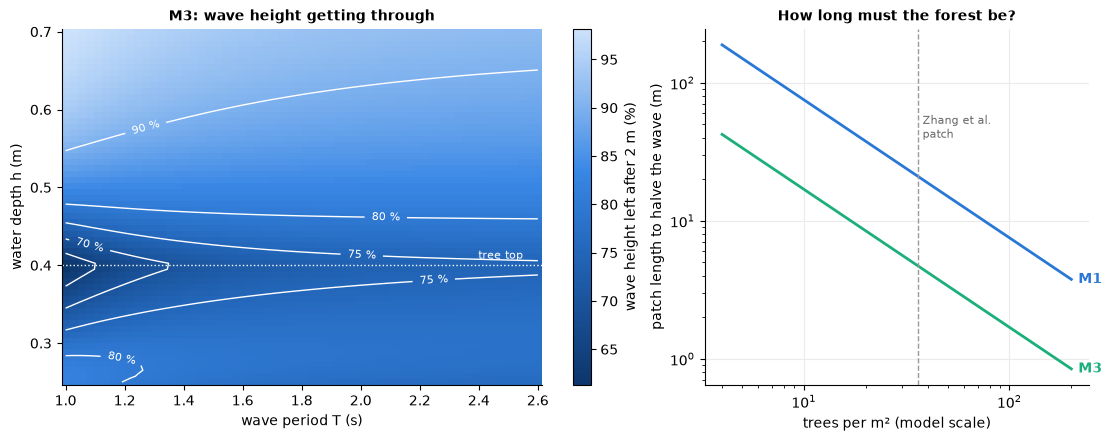

In [12]:
fig, (a1, a2) = plt.subplots(
    1, 2, figsize=(11, 4.3), layout="constrained", gridspec_kw={"width_ratios": [1.25, 1]}
)
periods, depths = np.linspace(1.0, 2.6, 60), np.linspace(0.25, 0.7, 60)
trans = np.array(
    [
        [
            sd.propagate(sd.RegularWave(0.08, T, h), PLANTS["M3"], 2.0, drag=2.0, x_out=[2.0]).H[0]
            / 0.08
            for T in periods
        ]
        for h in depths
    ]
)
im = a1.pcolormesh(periods, depths, 100 * trans, cmap=BLUES.reversed(), shading="auto")
cs = a1.contour(
    periods, depths, 100 * trans, levels=[65, 70, 75, 80, 90], colors="white", linewidths=1
)
a1.clabel(cs, fmt="%d %%", fontsize=8)
a1.axhline(0.4, color="white", ls=":", lw=1)
a1.text(2.55, 0.405, "tree top", color="white", ha="right", va="bottom", fontsize=8)
fig.colorbar(im, ax=a1, label="wave height left after 2 m (%)")
a1.set(
    xlabel="wave period T (s)", ylabel="water depth h (m)", title="M3: wave height getting through"
)
a1.grid(False)

density = np.geomspace(4, 200, 40)
w = sd.RegularWave(0.08, 1.4, 0.4)
for c in ("M1", "M3"):
    lengths = []
    for n in density:
        f = n / N_TREES
        veg = dataclasses.replace(
            PLANTS[c],
            layers=tuple(
                dataclasses.replace(layer, n_per_m2=layer.n_per_m2 * f)
                for layer in PLANTS[c].layers
            ),
        )
        lengths.append(1.0 / sd.propagate(w, veg, 2.0, drag=2.0).beta)  # H halves at βx = 1
    a2.plot(density, lengths, color=CFG[c], lw=2)
    a2.annotate(
        c,
        (density[-1], lengths[-1]),
        xytext=(5, 0),
        textcoords="offset points",
        color=CFG[c],
        weight="bold",
        va="center",
    )
a2.axvline(N_TREES, color="0.6", ls="--", lw=1)
a2.text(N_TREES * 1.05, 40, "Zhang et al.\npatch", fontsize=8, color="0.4")
a2.set(
    xscale="log",
    yscale="log",
    xlabel="trees per m² (model scale)",
    ylabel="patch length to halve the wave (m)",
    title="How long must the forest be?",
)
plt.show()

## 8. From the lab to the real world

Flume experiments are built small; Zhang et al.'s trees are one-tenth real size. Under
**Froude scaling**, the standard rule for wave models, lengths scale by λ, times and
velocities by √λ, and forces by λ³. Some quantities can't be kept equal, though. The
Reynolds number is λ^1.5 ≈ 32 times larger in reality at 1:10, which is one reason lab
drag laws may not transfer to the field. SADIE converts waves and plants between scales
and keeps track of which numbers are preserved.

In [13]:
lam = 10.0
print(f"{'quantity':<16}{'prototype / model at 1:10':>28}")
for q in ("length", "time", "velocity", "force", "beta", "kc", "ursell", "reynolds"):
    print(f"{q:<16}{froude.scale_factor(q, lam):>28.4g}")

wave_m = sd.RegularWave(0.08, 1.4, 0.4)
wave_p = froude.wave_to_prototype(wave_m, lam)
veg_m = PLANTS["M3"].depth_averaged(0.4)
veg_p = froude.vegetation_to_prototype(PLANTS["M3"], lam).depth_averaged(wave_p.depth)
print(f"\nlab wave:  H = {wave_m.H} m, T = {wave_m.T} s, h = {wave_m.depth} m")
print(f"real wave: H = {wave_p.H:.2f} m, T = {wave_p.T:.2f} s, h = {wave_p.depth:.1f} m")

quantity           prototype / model at 1:10
length                                    10
time                                   3.162
velocity                               3.162
force                                   1000
beta                                     0.1
kc                                         1
ursell                                     1
reynolds                               31.62

lab wave:  H = 0.08 m, T = 1.4 s, h = 0.4 m
real wave: H = 0.80 m, T = 4.43 s, h = 4.0 m


Now simulate the M3 forest at both scales with a Reynolds-number drag law fitted at
1:12 (`maza2017_re`). Plotted against distance in units of the tree height, the lab and
the full-size forest should damp the wave identically, provided the Reynolds number is
converted back to the scale the law was fitted at. SADIE does this when you pass
`scale=`. Leave it out and the law is fed a Reynolds number 32 times too large, so it
predicts the wrong drag and a different result.

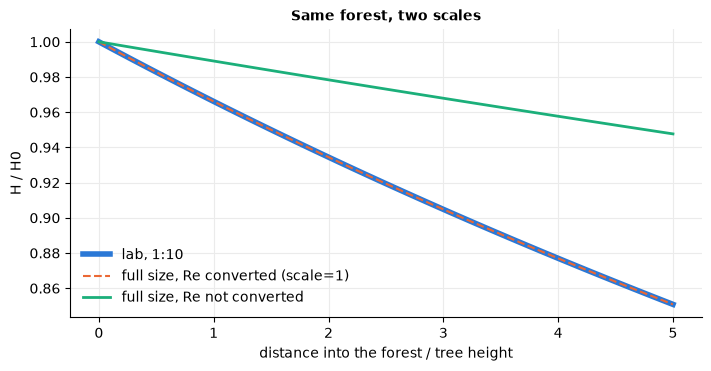

In [14]:
kw = {"drag": "maza2017_re", "cd_evaluation": "incident"}
xm = np.linspace(0, 2, 50)
lab = sd.propagate(wave_m, veg_m, 2.0, x_out=xm, scale=lam, **kw)
real = sd.propagate(wave_p, veg_p, 20.0, x_out=xm * lam, scale=1.0, **kw)
naive = sd.propagate(wave_p, veg_p, 20.0, x_out=xm * lam, **kw)
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
ax.plot(xm / 0.4, lab.H / wave_m.H, color=CFG["M1"], lw=4, label="lab, 1:10")
ax.plot(
    xm / 0.4,
    real.H / wave_p.H,
    color=CFG["M2"],
    lw=1.5,
    ls="--",
    label="full size, Re converted (scale=1)",
)
ax.plot(xm / 0.4, naive.H / wave_p.H, color=CFG["M3"], lw=2, label="full size, Re not converted")
ax.set(
    xlabel="distance into the forest / tree height",
    ylabel="H / H0",
    title="Same forest, two scales",
)
ax.legend()
plt.show()

## 9. Your own plant, your own data

Nothing above is specific to mangroves. Here is a made-up **salt-marsh** plant, built
from scratch:

- stems that taper from 6 mm at the base to 2 mm at the tip (a width that varies with
  height);
- a bushy layer of leaves halfway up;
- a home-made drag law of the kind you might fit to your own flume data.

The drag law and its numbers are invented for illustration. SADIE records them, checks
that the law stays inside its stated range, and flags it when it doesn't.

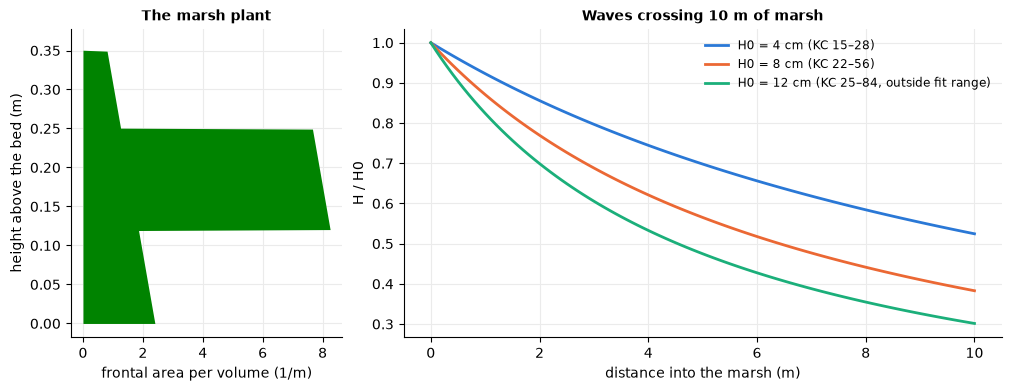

In [15]:
stems = sd.Layer(
    "stems",
    0.0,
    0.35,
    n_per_m2=400.0,
    frontal_width=lambda s: 0.006 - 0.004 * s / 0.35,
    solid_area=lambda s: np.pi / 4 * (0.006 - 0.004 * s / 0.35) ** 2,
)
leaves = sd.Layer(
    "leaves", 0.12, 0.25, n_per_m2=1600.0, frontal_width=0.004, solid_area=0.004 * 0.0005
)
marsh = sd.Vegetation(
    layers=(stems, leaves), name="illustrative salt marsh", reference_diameter=0.006
)
my_law = sd.drag.custom(
    "my_flume_fit",
    lambda kc: 1.0 + 8.0 / kc,
    "KC",
    length_scale="d",
    valid_range=(5.0, 60.0),
    citation="illustrative example, not a published fit",
)

fig, (a1, a2) = plt.subplots(
    1, 2, figsize=(10, 3.8), layout="constrained", gridspec_kw={"width_ratios": [1, 2.2]}
)
s = np.linspace(0, 0.36, 300)
a1.fill_betweenx(s, 0, marsh.frontal_area_profile(s), color=PART["canopy"], lw=0)
a1.set(
    xlabel="frontal area per volume (1/m)",
    ylabel="height above the bed (m)",
    title="The marsh plant",
)
for H, color in zip((0.04, 0.08, 0.12), (CFG["M1"], CFG["M2"], CFG["M3"]), strict=True):
    r = sd.propagate(
        sd.RegularWave(H, 1.6, 0.3),
        marsh,
        10.0,
        water=water,
        drag=my_law,
        x_out=np.linspace(0, 10, 101),
    )
    kc_lo, kc_hi = r.dimensionless["KC[my_flume_fit]"]["range"]
    a2.plot(
        r.x,
        r.H / H,
        color=color,
        lw=2,
        label=f"H0 = {100 * H:.0f} cm (KC {kc_lo:.0f}–{kc_hi:.0f}"
        f"{', outside fit range' if r.extrapolated else ''})",
    )
a2.set(xlabel="distance into the marsh (m)", ylabel="H / H0", title="Waves crossing 10 m of marsh")
a2.legend(fontsize=8.5)
plt.show()

Bigger waves lose a larger share of their height. Drag grows faster than the
energy the wave carries, which is the classic signature of vegetation damping and a
reason marshes and mangroves are most useful in storms.

## What SADIE does today, and what's next

| Capability | Status |
|---|---|
| Water properties from temperature and salinity | ✓ |
| Linear wave theory, with breaking and nonlinearity checks | ✓ |
| Plants as stacks of layers, any width profile, frontal area, SVF, characteristic lengths | ✓ |
| Wave damping: exact formula for constant $C_D$, numerical solution when $C_D$ varies | ✓ |
| Energy budget and the share of dissipation in each plant part | ✓ |
| Ten published mangrove drag laws, with ranges, sources and scales | ✓ |
| Zhang et al. (2023) mangrove models and test matrix | ✓ |
| Froude scaling of waves and plants; Reynolds-number conversion between scales | ✓ |
| Flexible plants (seagrass, kelp) that bend in the flow | next milestone |
| Analysing your own flume data: reflection, fitting β, inferring $C_D$ | planned |
| Designing experiments: measurability, coverage, Pareto trade-offs | planned |

The physics behind every result here (dispersion, the energy balance, the layered
dissipation, the energy budget and the scaling) is covered by SADIE's automated test
suite. The coming milestones add flexible plants, tools for analysing flume data and
inferring $C_D$, and tools for designing experiments.